<a href="https://colab.research.google.com/github/namukwayavanessa-hub/applied_project/blob/main/applieddatascience.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from datasets import load_dataset

ds = load_dataset("stanfordnlp/imdb")
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [4]:
train_full = ds["train"].to_pandas()
test_full = ds["test"].to_pandas()
print(train_full.shape, test_full.shape)
train_full.head(30)

(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
5,I would put this at the top of my list of film...,0
6,Whoever wrote the screenplay for this movie ob...,0
7,"When I first saw a glimpse of this movie, I qu...",0
8,"Who are these ""They""- the actors? the filmmake...",0
9,This is said to be a personal film for Peter B...,0


In [5]:
# How many positive and negative reviews
print(train_full["label"].value_counts())

label
0    12500
1    12500
Name: count, dtype: int64


In [6]:
# Split each review by spaces and count the number of words
word_counts = train_full['text'].str.split().str.len()

# Calculate and print the average, shortest, and longest review lengths
print("Average review length:", int(word_counts.mean()), "words")
print("Shortest review:", word_counts.min(), "words")
print("Longest review:", word_counts.max(), "words")

Average review length: 233 words
Shortest review: 10 words
Longest review: 2470 words


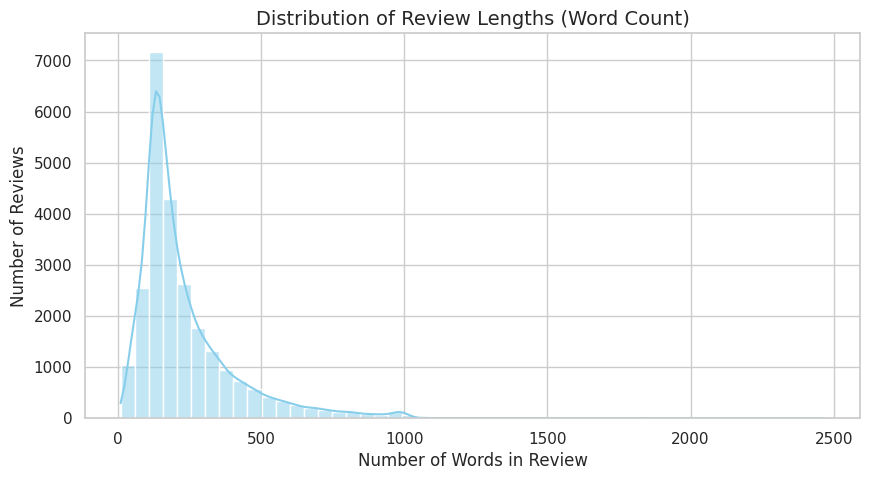

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a histogram to visualize the distribution of review lengths
plt.figure(figsize=(10, 5))
sns.histplot(word_counts, bins=50, kde=True, color='skyblue')

# Add labels and a title
plt.title('Distribution of Review Lengths (Word Count)', fontsize=14)
plt.xlabel('Number of Words in Review', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

# Display the plot
plt.show()

In [8]:
# Take the first 3 reviews from the training dataset
examples = train_full.head(3)

# Loop through each review and print its index, label, and the text itself
for index, row in examples.iterrows():
    print(f"--- Review #{index + 1} ---")
    # Map numerical label to human-readable sentiment (0 = Negative, 1 = Positive)
    sentiment = "Positive" if row['label'] == 1 else "Negative"
    print(f"Sentiment: {sentiment}")
    print(f"Review Text:\n{row['text']}\n")

--- Review #1 ---
Sentiment: Negative
Review Text:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the

In [9]:
from sklearn.model_selection import train_test_split

# Split the train_full data into 80% training and 20% validation sets
# We set a random_state to make sure the split is reproducible
train_split, val_split = train_test_split(train_full, test_size=0.2, random_state=42)

# Display the sizes of the splits to confirm
print(f"Original training size: {len(train_full)}")
print(f"New training split size: {len(train_split)}")
print(f"Validation split size: {len(val_split)}")

Original training size: 25000
New training split size: 20000
Validation split size: 5000
